Loss: start 7.838, end 0.0017
Words predicted correctly: 100.0%
Captions predicted perfectly: 16 of 16


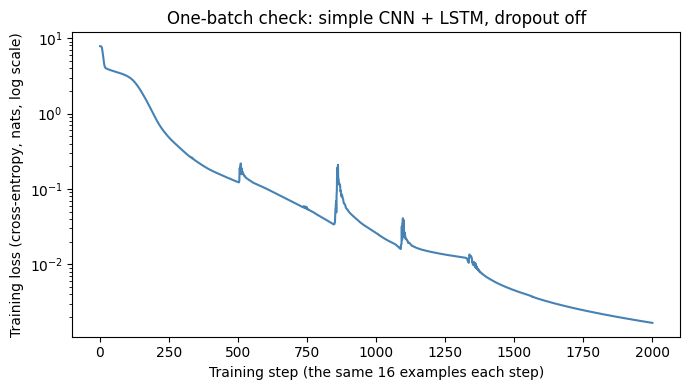

In [2]:
# One-batch check: can the model memorise 16 training examples? (dropout off)
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow import keras
from captioning.clean import load_config
from captioning.pipeline import make_dataset, load_vocab
from captioning.models.simple_deep import build_model

cfg = load_config()
random.seed(cfg["seed"])
np.random.seed(cfg["seed"])
tf.random.set_seed(cfg["seed"])
vocab = load_vocab(cfg)
FIG_DIR = Path("reports/figures")

(images, caption_in), caption_out = next(iter(make_dataset("train", cfg, encoder="raw")))
images, caption_in, caption_out = images[:16], caption_in[:16], caption_out[:16]

model = build_model(len(vocab), caption_in.shape[1], dropout=0.0)
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True, ignore_class=0))
history = model.fit((images, caption_in), caption_out, batch_size=16, epochs=2000, verbose=0)
losses = history.history["loss"]

target = caption_out.numpy()
pred = np.argmax(model((images, caption_in), training=False).numpy(), axis=-1)
mask = target != 0                                   # ignore <pad> positions
word_accuracy = (pred[mask] == target[mask]).mean() * 100
captions_perfect = sum((pred[i][mask[i]] == target[i][mask[i]]).all() for i in range(16))

print(f"Loss: start {losses[0]:.3f}, end {losses[-1]:.4f}")
print(f"Words predicted correctly: {word_accuracy:.1f}%")
print(f"Captions predicted perfectly: {captions_perfect} of 16")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, len(losses) + 1), losses, color="steelblue")
ax.set_yscale("log")
ax.set_xlabel("Training step (the same 16 examples each step)")
ax.set_ylabel("Training loss (cross-entropy, nats, log scale)")
ax.set_title("One-batch check: simple CNN + LSTM, dropout off")
fig.tight_layout()
fig.savefig(FIG_DIR / "m4_fig1_one_batch.png", dpi=200)
plt.show()